In [ ]:
import pandas as pd
df = pd.read_csv(
    "/content/swap_events.csv",
    nrows=100000
)

df.to_csv("swap_events_sample.csv", index=False)

In [ ]:
from google.colab import files

files.download("swap_events_sample.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np
stations = pd.read_csv("stations.csv")
riders = pd.read_csv("riders.csv")
batteries = pd.read_csv("batteries.csv")
support_tickets = pd.read_csv("support_tickets.csv")
city_context = pd.read_csv("city_daily_context.csv")
fleet_partners = pd.read_csv("fleet_partners.csv")
station_status = pd.read_csv("station_hourly_status.csv")

In [ ]:
datasets = {
    "Stations": stations,
    "Riders": riders,
    "Batteries": batteries,
    "Support Tickets": support_tickets,
    "City Context": city_context,
    "Fleet Partners": fleet_partners,
    "Station Status": station_status
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

Stations: 152 rows × 22 columns
Riders: 20,000 rows × 12 columns
Batteries: 6,500 rows × 13 columns
Support Tickets: 44,000 rows × 12 columns
City Context: 3,282 rows × 12 columns
Fleet Partners: 12 rows × 12 columns
Station Status: 1,487,712 rows × 14 columns


In [ ]:
for name, df in datasets.items():
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print("Shape:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())

    missing = df.isna().sum()
    missing = missing[missing > 0]

    print("\nMissing values:")
    if len(missing) == 0:
        print("No missing values")
    else:
        print(missing)


Stations
Shape: (152, 22)
Duplicate rows: 0

Missing values:
decommissioned_date              151
competitor_within_1_5km_since    142
dtype: int64

Riders
Shape: (20000, 12)
Duplicate rows: 0

Missing values:
partner_id        7628
declared_shift    3662
age_band          1547
dtype: int64

Batteries
Shape: (6500, 13)
Duplicate rows: 0

Missing values:
retired_date         5062
retirement_reason    5062
dtype: int64

Support Tickets
Shape: (44000, 12)
Duplicate rows: 0

Missing values:
station_id           2227
battery_id          13235
resolution_hours     6112
csat_score          28871
dtype: int64

City Context
Shape: (3282, 12)
Duplicate rows: 0

Missing values:
festival_or_event    3172
dtype: int64

Fleet Partners
Shape: (12, 12)
Duplicate rows: 0

Missing values:
amendment_date                  11
discount_pct_after_amendment    11
dtype: int64

Station Status
Shape: (1487712, 14)
Duplicate rows: 0

Missing values:
charged_2w_avg          9384
charged_2w_min          9384
char

In [ ]:
print("STATIONS")
print("Cities:", stations["city"].unique())
print("Charger generations:", stations["charger_generation"].unique())
print("Expansion waves:", stations["expansion_wave"].unique())

print("\nRIDERS")
print("Vehicle classes:", riders["vehicle_class"].unique())
print("Plan types:", riders["plan_type"].unique())
print("Signup channels:", riders["signup_channel"].unique())

print("\nBATTERIES")
print("Suppliers:", batteries["supplier"].unique())
print("Pack types:", batteries["pack_type"].unique())

print("\nFLEET PARTNERS")
print(fleet_partners["partner_segment"].unique())

print("\nSTATION STATUS")
print(station_status["telemetry_status"].value_counts(dropna=False))

STATIONS
Cities: ['Bengaluru' 'Delhi NCR' 'Hyderabad' 'Pune' 'Mumbai' 'Jaipur']
Charger generations: ['Gen1' 'Gen2' 'Gen3']
Expansion waves: ['Launch' 'Wave1_2024H2' 'Wave2_2025H1']

RIDERS
Vehicle classes: ['3W' '2W']
Plan types: ['partner_billed' 'pay_as_you_go' 'prepaid_pack']
Signup channels: ['field_agent' 'partner_onboarding' 'app_store' 'referral']

BATTERIES
Suppliers: ['Cellora' 'Kyron' 'Amptek']
Pack types: ['2W_2.1kWh' '3W_4.8kWh']

FLEET PARTNERS
['food_delivery' 'ecom_logistics' 'quick_commerce' 'cargo_3w' 'bike_taxi']

STATION STATUS
telemetry_status
ok         1441341
partial      36987
missing       9384
Name: count, dtype: int64


In [ ]:
# Make copies so the original imported data remains unchanged

stations_clean = stations.copy()
riders_clean = riders.copy()
batteries_clean = batteries.copy()
support_clean = support_tickets.copy()
city_context_clean = city_context.copy()
fleet_clean = fleet_partners.copy()
station_status_clean = station_status.copy()

In [ ]:
stations_clean["commissioned_date"] = pd.to_datetime(
    stations_clean["commissioned_date"], errors="coerce"
)

stations_clean["decommissioned_date"] = pd.to_datetime(
    stations_clean["decommissioned_date"], errors="coerce"
)

stations_clean["firmware_updated_date"] = pd.to_datetime(
    stations_clean["firmware_updated_date"], errors="coerce"
)

riders_clean["signup_date"] = pd.to_datetime(
    riders_clean["signup_date"], errors="coerce"
)

batteries_clean["manufacture_date"] = pd.to_datetime(
    batteries_clean["manufacture_date"], errors="coerce"
)

batteries_clean["commission_date"] = pd.to_datetime(
    batteries_clean["commission_date"], errors="coerce"
)

batteries_clean["retired_date"] = pd.to_datetime(
    batteries_clean["retired_date"], errors="coerce"
)

support_clean["created_ts"] = pd.to_datetime(
    support_clean["created_ts"], errors="coerce"
)

city_context_clean["date"] = pd.to_datetime(
    city_context_clean["date"], errors="coerce"
)

fleet_clean["contract_start_date"] = pd.to_datetime(
    fleet_clean["contract_start_date"], errors="coerce"
)

fleet_clean["amendment_date"] = pd.to_datetime(
    fleet_clean["amendment_date"], errors="coerce"
)

station_status_clean["hour_start"] = pd.to_datetime(
    station_status_clean["hour_start"], errors="coerce"
)

print("Date conversion completed successfully.")

Date conversion completed successfully.


In [ ]:
print("Stations:")
print("Commissioned:", stations_clean["commissioned_date"].min(), "to", stations_clean["commissioned_date"].max())

print("\nRiders:")
print("Signup:", riders_clean["signup_date"].min(), "to", riders_clean["signup_date"].max())

print("\nBatteries:")
print("Manufactured:", batteries_clean["manufacture_date"].min(), "to", batteries_clean["manufacture_date"].max())
print("Commissioned:", batteries_clean["commission_date"].min(), "to", batteries_clean["commission_date"].max())

print("\nSupport Tickets:")
print("Created:", support_clean["created_ts"].min(), "to", support_clean["created_ts"].max())

print("\nCity Context:")
print("Date:", city_context_clean["date"].min(), "to", city_context_clean["date"].max())

print("\nStation Status:")
print("Hour:", station_status_clean["hour_start"].min(), "to", station_status_clean["hour_start"].max())

Stations:
Commissioned: 2023-06-01 00:00:00 to 2025-04-28 00:00:00

Riders:
Signup: 2023-03-08 00:00:00 to 2025-06-30 00:00:00

Batteries:
Manufactured: 2023-01-07 00:00:00 to 2025-06-02 00:00:00
Commissioned: 2023-03-01 00:00:00 to 2025-06-15 00:00:00

Support Tickets:
Created: 2023-03-09 00:00:00 to 2025-07-01 08:09:52

City Context:
Date: 2024-01-01 00:00:00 to 2025-06-30 00:00:00

Station Status:
Hour: 2024-01-01 00:00:00 to 2025-06-30 23:00:00


In [ ]:
print("=== RELATIONSHIP CHECKS ===")

print("\nStation IDs referenced by station status but missing in stations:")
print(
    (~station_status_clean["station_id"].isin(stations_clean["station_id"]))
    .sum()
)

print("\nRider IDs referenced in support tickets but missing in riders:")
print(
    (~support_clean["rider_id"].isin(riders_clean["rider_id"]))
    .sum()
)

print("\nStation IDs referenced in support tickets but missing in stations:")
print(
    (~support_clean["station_id"].dropna().isin(stations_clean["station_id"]))
    .sum()
)

print("\nBattery IDs referenced in support tickets but missing in batteries:")
print(
    (~support_clean["battery_id"].dropna().isin(batteries_clean["battery_id"]))
    .sum()
)

print("\nFleet partner IDs referenced by riders but missing in fleet partners:")
print(
    (
        riders_clean["partner_id"].dropna().isin(fleet_clean["partner_id"]) == False
    ).sum()
)

=== RELATIONSHIP CHECKS ===

Station IDs referenced by station status but missing in stations:
0

Rider IDs referenced in support tickets but missing in riders:
0

Station IDs referenced in support tickets but missing in stations:
0

Battery IDs referenced in support tickets but missing in batteries:
0

Fleet partner IDs referenced by riders but missing in fleet partners:
0


In [ ]:
quality_summary = pd.DataFrame({
    "Dataset": [
        "Stations",
        "Riders",
        "Batteries",
        "Support Tickets",
        "City Context",
        "Fleet Partners",
        "Station Status"
    ],
    "Rows": [
        len(stations_clean),
        len(riders_clean),
        len(batteries_clean),
        len(support_clean),
        len(city_context_clean),
        len(fleet_clean),
        len(station_status_clean)
    ],
    "Duplicate Rows": [
        stations_clean.duplicated().sum(),
        riders_clean.duplicated().sum(),
        batteries_clean.duplicated().sum(),
        support_clean.duplicated().sum(),
        city_context_clean.duplicated().sum(),
        fleet_clean.duplicated().sum(),
        station_status_clean.duplicated().sum()
    ]
})

display(quality_summary)

,Dataset,Rows,Duplicate Rows
0,Stations,152,0
1,Riders,20000,0
2,Batteries,6500,0
3,Support Tickets,44000,0
4,City Context,3282,0
5,Fleet Partners,12,0
6,Station Status,1487712,0


In [ ]:
missing_summary = pd.DataFrame({
    "Dataset": [
        "Stations",
        "Riders",
        "Batteries",
        "Support Tickets",
        "City Context",
        "Fleet Partners",
        "Station Status"
    ],
    "Missing Values": [
        stations_clean.isna().sum().sum(),
        riders_clean.isna().sum().sum(),
        batteries_clean.isna().sum().sum(),
        support_clean.isna().sum().sum(),
        city_context_clean.isna().sum().sum(),
        fleet_clean.isna().sum().sum(),
        station_status_clean.isna().sum().sum()
    ]
})

display(missing_summary)

,Dataset,Missing Values
0,Stations,293
1,Riders,12837
2,Batteries,10124
3,Support Tickets,50445
4,City Context,3172
5,Fleet Partners,22
6,Station Status,896880


In [ ]:
datasets = {
    "Stations": stations_clean,
    "Riders": riders_clean,
    "Batteries": batteries_clean,
    "Support Tickets": support_clean,
    "City Context": city_context_clean,
    "Fleet Partners": fleet_clean,
    "Station Status": station_status_clean
}

for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    print(f"\n{'=' * 20} {name} {'=' * 20}")
    print(missing)


==================== Stations ====================
decommissioned_date              151
competitor_within_1_5km_since    142
dtype: int64

==================== Riders ====================
partner_id        7628
declared_shift    3662
age_band          1547
dtype: int64

==================== Batteries ====================
retired_date         5062
retirement_reason    5062
dtype: int64

==================== Support Tickets ====================
csat_score          28871
battery_id          13235
resolution_hours     6112
station_id           2227
dtype: int64

==================== City Context ====================
festival_or_event    3172
dtype: int64

==================== Fleet Partners ====================
amendment_date                  11
discount_pct_after_amendment    11
dtype: int64

==================== Station Status ====================
charged_3w_min        821808
charged_2w_avg          9384
charged_2w_min          9384
packs_charging          9384
packs_quarantined       9

In [ ]:
print(stations_clean.columns.tolist())

['station_id', 'city', 'zone', 'latitude', 'longitude', 'location_type', 'host_type', 'commissioned_date', 'decommissioned_date', 'expansion_wave', 'charger_generation', 'slots_2w', 'slots_3w', 'inventory_target_2w', 'inventory_target_3w', 'monthly_rent_inr', 'monthly_maintenance_inr', 'grid_tariff_inr_kwh', 'connectivity_tier', 'firmware_version', 'firmware_updated_date', 'competitor_within_1_5km_since']


In [ ]:
station_3w_check = (
    stations_clean
    .groupby("slots_3w", dropna=False)
    .agg(
        stations=("station_id", "nunique")
    )
    .reset_index()
)

display(station_3w_check)

,slots_3w,stations
0,0,85
1,4,32
2,6,35


In [ ]:
status_3w_check = (
    station_status_clean
    .merge(
        stations_clean[["station_id", "slots_3w"]],
        on="station_id",
        how="left"
    )
    .groupby("slots_3w", dropna=False)
    .agg(
        status_rows=("station_id", "size"),
        missing_charged_3w=("charged_3w_min", lambda x: x.isna().sum())
    )
    .reset_index()
)

status_3w_check["missing_pct"] = (
    status_3w_check["missing_charged_3w"]
    / status_3w_check["status_rows"]
    * 100
)

display(status_3w_check)

,slots_3w,status_rows,missing_charged_3w,missing_pct
0,0,818160,818160,100.000000
1,4,311544,1043,0.334784
2,6,358008,2605,0.727637


In [ ]:
telemetry_missing = pd.DataFrame({
    "Column": [
        "charged_2w_avg",
        "charged_2w_min",
        "charged_3w_min",
        "packs_charging",
        "packs_quarantined",
        "ambient_temp_c",
        "cabinet_temp_c",
        "avg_charge_minutes",
        "grid_kwh"
    ],
    "Missing": [
        station_status_clean["charged_2w_avg"].isna().sum(),
        station_status_clean["charged_2w_min"].isna().sum(),
        station_status_clean["charged_3w_min"].isna().sum(),
        station_status_clean["packs_charging"].isna().sum(),
        station_status_clean["packs_quarantined"].isna().sum(),
        station_status_clean["ambient_temp_c"].isna().sum(),
        station_status_clean["cabinet_temp_c"].isna().sum(),
        station_status_clean["avg_charge_minutes"].isna().sum(),
        station_status_clean["grid_kwh"].isna().sum()
    ]
})

telemetry_missing["Missing %"] = (
    telemetry_missing["Missing"] / len(station_status_clean) * 100
)

display(telemetry_missing)

,Column,Missing,Missing %
0,charged_2w_avg,9384,0.630767
1,charged_2w_min,9384,0.630767
2,charged_3w_min,821808,55.239724
3,packs_charging,9384,0.630767
4,packs_quarantined,9384,0.630767
5,ambient_temp_c,9384,0.630767
6,cabinet_temp_c,9384,0.630767
7,avg_charge_minutes,9384,0.630767
8,grid_kwh,9384,0.630767


In [ ]:
telemetry_status_summary = (
    station_status_clean["telemetry_status"]
    .value_counts(dropna=False)
    .rename_axis("telemetry_status")
    .reset_index(name="rows")
)

telemetry_status_summary["percentage"] = (
    telemetry_status_summary["rows"]
    / len(station_status_clean)
    * 100
)

display(telemetry_status_summary)

,telemetry_status,rows,percentage
0,ok,1441341,96.883066
1,partial,36987,2.486167
2,missing,9384,0.630767


In [ ]:
test_station_check = stations_clean[
    stations_clean["station_id"].astype(str).str.startswith("STN-TST")
]

print("Test stations:", len(test_station_check))
print("\nTest station cities:")
print(test_station_check["city"].value_counts(dropna=False))

print("\nTest station IDs:")
print(test_station_check["station_id"].tolist())

Test stations: 2

Test station cities:
city
Bengaluru    2
Name: count, dtype: int64

Test station IDs:
['STN-TST-01', 'STN-TST-02']


In [ ]:
stations_analysis = stations_clean[
    ~stations_clean["station_id"].astype(str).str.startswith("STN-TST")
].copy()

print("Total stations:", len(stations_clean))
print("Test stations excluded:", len(stations_clean) - len(stations_analysis))
print("Analysis stations:", len(stations_analysis))

print("\nStations by city:")
print(stations_analysis["city"].value_counts())

Total stations: 152
Test stations excluded: 2
Analysis stations: 150

Stations by city:
city
Bengaluru    32
Delhi NCR    30
Hyderabad    26
Pune         22
Mumbai       22
Jaipur       18
Name: count, dtype: int64


In [ ]:
# Standardize key categorical/text fields
for df, cols in [
    (stations_analysis, ["station_id", "city", "zone", "location_type",
                         "host_type", "charger_generation", "expansion_wave",
                         "connectivity_tier", "firmware_version"]),
    (riders_clean, ["rider_id", "city", "home_city", "vehicle_class",
                    "plan_type", "signup_channel", "declared_shift"]),
    (batteries_clean, ["battery_id", "supplier", "pack_type",
                       "manufacturing_lot", "retirement_reason"]),
    (fleet_clean, ["partner_id", "partner_name", "segment"]),
    (support_clean, ["ticket_id", "rider_id", "station_id",
                     "battery_id", "category", "priority", "status"])
]:
    for col in cols:
        if col in df.columns:
            df[col] = df[col].astype("string").str.strip()

print("Key text fields standardized.")

Key text fields standardized.


In [ ]:
swap_columns = pd.read_csv(
    "swap_events.csv.gz",
    nrows=0
).columns.tolist()

print("Number of columns:", len(swap_columns))
print("\nColumns:")
print(swap_columns)

FileNotFoundError: [Errno 2] No such file or directory: 'swap_events.csv.gz'

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'swap_events_sample.csv', 'fleet_partners.csv', 'support_tickets.csv', 'city_daily_context.csv', 'station_hourly_status.csv', 'stations.csv', 'batteries.csv', 'swap_events.csv', 'riders.csv', 'sample_data']


In [ ]:
import os

file_path = "/content/swap_events.csv"

print("File exists:", os.path.exists(file_path))
print("File size (GB):", round(os.path.getsize(file_path) / (1024**3), 2))

File exists: True
File size (GB): 0.49


In [ ]:
swap_columns = pd.read_csv(
    "/content/swap_events.csv",
    nrows=0
).columns.tolist()

print("Number of columns:", len(swap_columns))
print("\nColumns:")
print(swap_columns)

Number of columns: 22

Columns:
['event_id', 'rider_id', 'station_id', 'event_ts', 'event_type', 'attempt_seq', 'queue_wait_sec', 'battery_in_id', 'battery_out_id', 'soc_in_pct', 'soh_in_pct', 'soc_out_pct', 'soh_out_pct', 'km_since_last_swap', 'tariff_code', 'list_price_inr', 'discount_inr', 'amount_charged_inr', 'payment_mode', 'energy_to_recharge_kwh', 'station_firmware', 'sync_mode']


In [ ]:
sample = pd.read_csv(
    "/content/swap_events.csv",
    nrows=10000
)

print("Shape:", sample.shape)
print("\nData types:")
print(sample.dtypes)

print("\nMissing values:")
print(sample.isna().sum())

Shape: (10000, 22)

Data types:
event_id                   object
rider_id                   object
station_id                 object
event_ts                   object
event_type                 object
attempt_seq                 int64
queue_wait_sec              int64
battery_in_id              object
battery_out_id             object
soc_in_pct                float64
soh_in_pct                float64
soc_out_pct               float64
soh_out_pct               float64
km_since_last_swap        float64
tariff_code                object
list_price_inr            float64
discount_inr              float64
amount_charged_inr        float64
payment_mode               object
energy_to_recharge_kwh    float64
station_firmware           object
sync_mode                  object
dtype: object

Missing values:
event_id                    0
rider_id                    0
station_id                  0
event_ts                    0
event_type                  0
attempt_seq                 0
queue_wai

In [ ]:
print("Event type distribution:")
print(sample["event_type"].value_counts(dropna=False))

print("\nMissing values by event type:")
print(
    sample.groupby("event_type", dropna=False)[
        [
            "battery_in_id",
            "battery_out_id",
            "soc_in_pct",
            "soh_in_pct",
            "soc_out_pct",
            "soh_out_pct",
            "km_since_last_swap",
            "energy_to_recharge_kwh"
        ]
    ]
    .apply(lambda x: x.isna().sum())
)

Event type distribution:
event_type
swap_completed               9542
failed_no_charged_battery     258
abandoned_queue               125
cancelled_by_rider             47
failed_system_error            28
Name: count, dtype: int64

Missing values by event type:
                           battery_in_id  battery_out_id  soc_in_pct  \
event_type                                                             
abandoned_queue                        0             125           0   
cancelled_by_rider                    47              47          47   
failed_no_charged_battery              0             258           0   
failed_system_error                   28              28          28   
swap_completed                         0               0           0   

                           soh_in_pct  soc_out_pct  soh_out_pct  \
event_type                                                        
abandoned_queue                     0          125          125   
cancelled_by_rider             

In [ ]:
print("Exact duplicate rows:", sample.duplicated().sum())

print("\nDuplicate event IDs:", sample["event_id"].duplicated().sum())

print("\nSync mode distribution:")
print(sample["sync_mode"].value_counts(dropna=False))

print("\nStation firmware distribution:")
print(sample["station_firmware"].value_counts(dropna=False))

Exact duplicate rows: 0

Duplicate event IDs: 0

Sync mode distribution:
sync_mode
realtime         8484
offline_batch    1516
Name: count, dtype: int64

Station firmware distribution:
station_firmware
v3.2.1    5970
v3.2.0    4030
Name: count, dtype: int64


In [ ]:
import pandas as pd

file_path = "/content/swap_events.csv"

chunk_size = 250_000
cleaned_chunks = []

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    # Standardize text columns
    text_cols = [
        "event_id", "rider_id", "station_id", "event_type",
        "battery_in_id", "battery_out_id", "tariff_code",
        "payment_mode", "station_firmware", "sync_mode"
    ]

    for col in text_cols:
        chunk[col] = chunk[col].astype("string").str.strip()

    # Convert timestamp
    chunk["event_ts"] = pd.to_datetime(chunk["event_ts"], errors="coerce")

    cleaned_chunks.append(chunk)

    print(f"Processed: {len(cleaned_chunks) * chunk_size:,} rows")

swap_events_clean = pd.concat(cleaned_chunks, ignore_index=True)

print("\nFinal shape:", swap_events_clean.shape)
print("Invalid timestamps:", swap_events_clean["event_ts"].isna().sum())

Processed: 250,000 rows
Processed: 500,000 rows
Processed: 750,000 rows
Processed: 1,000,000 rows
Processed: 1,250,000 rows
Processed: 1,500,000 rows
Processed: 1,750,000 rows
Processed: 2,000,000 rows
Processed: 2,250,000 rows
Processed: 2,500,000 rows
Processed: 2,750,000 rows
Processed: 3,000,000 rows
Processed: 3,250,000 rows

Final shape: (3021830, 22)
Invalid timestamps: 0


In [ ]:
print("Exact duplicate rows:", swap_events_clean.duplicated().sum())
print("Duplicate event IDs:", swap_events_clean["event_id"].duplicated().sum())

Exact duplicate rows: 0
Duplicate event IDs: 0


In [ ]:
offline = swap_events_clean[
    swap_events_clean["sync_mode"] == "offline_batch"
].copy()

print("Offline-batch rows:", len(offline))

print("\nOffline-batch by event type:")
print(offline["event_type"].value_counts())

print("\nOffline-batch by station:")
print(offline["station_id"].nunique())

Offline-batch rows: 464853

Offline-batch by event type:
event_type
swap_completed               439504
failed_no_charged_battery     14389
abandoned_queue                7594
cancelled_by_rider             2004
failed_system_error            1362
Name: count, dtype: Int64

Offline-batch by station:
51


In [ ]:
offline_check = offline.sort_values(
    ["rider_id", "station_id", "event_ts", "event_type"]
).copy()

offline_check["time_diff_sec"] = (
    offline_check.groupby(["rider_id", "station_id", "event_type"])["event_ts"]
    .diff()
    .dt.total_seconds()
)

print("Offline-batch events within 60 seconds of the previous same-rider/station/event-type:")
print((offline_check["time_diff_sec"].between(0, 60)).sum())

print("\nTime difference summary (seconds):")
print(offline_check["time_diff_sec"].describe())

Offline-batch events within 60 seconds of the previous same-rider/station/event-type:
93

Time difference summary (seconds):
count    3.894080e+05
mean     1.278135e+06
std      2.897019e+06
min      1.000000e+00
25%      1.048998e+05
50%      2.585235e+05
75%      8.005955e+05
max      3.902194e+07
Name: time_diff_sec, dtype: float64


In [ ]:
near_dupes = offline_check[
    offline_check["time_diff_sec"].between(0, 60)
].copy()

print("Candidate near-duplicates:", len(near_dupes))

print("\nCandidate event types:")
print(near_dupes["event_type"].value_counts())

print("\nCandidate time differences:")
print(near_dupes["time_diff_sec"].describe())

print("\nSame event characteristics:")
print(
    near_dupes[
        [
            "rider_id", "station_id", "event_ts", "event_type",
            "attempt_seq", "battery_in_id", "battery_out_id",
            "amount_charged_inr", "energy_to_recharge_kwh"
        ]
    ].head(20).to_string(index=False)
)

Candidate near-duplicates: 93

Candidate event types:
event_type
swap_completed    93
Name: count, dtype: Int64

Candidate time differences:
count    93.000000
mean     31.215054
std      17.454817
min       1.000000
25%      17.000000
50%      32.000000
75%      46.000000
max      60.000000
Name: time_diff_sec, dtype: float64

Same event characteristics:
  rider_id  station_id            event_ts     event_type  attempt_seq battery_in_id battery_out_id  amount_charged_inr  energy_to_recharge_kwh
RD-1000426 STN-JAI-138 2024-09-16 20:55:11 swap_completed            1 BAT-2W-102935  BAT-2W-104342               57.20                   2.184
RD-1000435 STN-MUM-116 2024-12-14 12:56:24 swap_completed            1 BAT-2W-102200  BAT-2W-103743               46.80                   2.000
RD-1000544 STN-PUN-094 2024-03-10 21:50:02 swap_completed            1 BAT-2W-104095  BAT-2W-106028               55.20                   2.048
RD-1000558 STN-HYD-067 2024-06-25 10:49:57 swap_completed         

In [ ]:
numeric_cols = [
    "queue_wait_sec",
    "soc_in_pct",
    "soh_in_pct",
    "soc_out_pct",
    "soh_out_pct",
    "km_since_last_swap",
    "list_price_inr",
    "discount_inr",
    "amount_charged_inr",
    "energy_to_recharge_kwh"
]

print(swap_events_clean[numeric_cols].describe().T)

                            count        mean         std     min      25%  \
queue_wait_sec          3021830.0  243.033361  161.699294   0.000  138.000   
soc_in_pct              2999795.0    9.289501    4.447380   1.000    6.000   
soh_in_pct              2999795.0   90.933602    5.478615  68.400   87.300   
soc_out_pct             2863643.0   96.664187    3.373003  80.000   95.900   
soh_out_pct             2863643.0   90.904816    5.274803  68.100   87.300   
km_since_last_swap      2999795.0   64.626894   19.796779 -20.000   54.900   
list_price_inr          3021829.0   68.506501   13.840168  60.000   65.000   
discount_inr            3021829.0    5.645953    5.364127   0.000    0.000   
amount_charged_inr      3021829.0   60.334923   19.855191   0.000   54.600   
energy_to_recharge_kwh  2863642.0    2.154611    0.810755   1.043    1.788   

                            50%     75%       max  
queue_wait_sec          206.000  305.00  2400.000  
soc_in_pct                9.300   12.

In [ ]:
# Clean known invalid numeric values

# SOC/SOH cannot exceed 100%
for col in ["soc_in_pct", "soc_out_pct", "soh_in_pct", "soh_out_pct"]:
    swap_events_clean.loc[
        swap_events_clean[col] > 100, col
    ] = 100

# Distance cannot be negative
swap_events_clean.loc[
    swap_events_clean["km_since_last_swap"] < 0,
    "km_since_last_swap"
] = pd.NA

print("Remaining SOC/SOH > 100:",
      (swap_events_clean[["soc_in_pct","soc_out_pct","soh_in_pct","soh_out_pct"]] > 100).sum().sum())

print("Negative km values:",
      (swap_events_clean["km_since_last_swap"] < 0).sum())

print("Missing km values:",
      swap_events_clean["km_since_last_swap"].isna().sum())

Remaining SOC/SOH > 100: 0
Negative km values: 0
Missing km values: 28175


In [ ]:
# 1. Correct known firmware timestamp issue
mask = (
    (swap_events_clean["station_firmware"] == "v3.2.0") &
    (swap_events_clean["event_ts"] >= "2025-03-10") &
    (swap_events_clean["event_ts"] <= "2025-04-14 23:59:59")
)

swap_events_clean.loc[mask, "event_ts"] += pd.Timedelta(hours=5, minutes=30)

# 2. Exclude test stations from network analysis
test_stations = ["STN-TST-01", "STN-TST-02"]

before = len(swap_events_clean)

swap_events_clean = swap_events_clean[
    ~swap_events_clean["station_id"].isin(test_stations)
].copy()

after = len(swap_events_clean)

print("Firmware timestamps corrected:", mask.sum())
print("Test-station rows removed:", before - after)
print("Final cleaned shape:", swap_events_clean.shape)

Firmware timestamps corrected: 135659
Test-station rows removed: 51040
Final cleaned shape: (2970790, 22)


In [ ]:
print("FINAL CLEANING VALIDATION")
print("-" * 40)

print("Rows:", len(swap_events_clean))
print("Columns:", len(swap_events_clean.columns))
print("Duplicate event IDs:", swap_events_clean["event_id"].duplicated().sum())
print("Invalid timestamps:", swap_events_clean["event_ts"].isna().sum())
print("Test-station rows:", swap_events_clean["station_id"].isin(test_stations).sum())

print("\nEvent types:")
print(swap_events_clean["event_type"].value_counts())

# Save cleaned dataset
output_path = "/content/swap_events_clean.csv"
swap_events_clean.to_csv(output_path, index=False)

print("\nSaved:", output_path)

FINAL CLEANING VALIDATION
----------------------------------------
Rows: 2970790
Columns: 22
Duplicate event IDs: 0
Invalid timestamps: 0
Test-station rows: 0

Event types:
event_type
swap_completed               2814959
failed_no_charged_battery      88160
abandoned_queue                45991
cancelled_by_rider             12779
failed_system_error             8901
Name: count, dtype: Int64

Saved: /content/swap_events_clean.csv


In [ ]:
# Monthly Network KPI Table

monthly_kpis = (
    swap_events_clean
    .assign(month=swap_events_clean["event_ts"].dt.to_period("M").astype(str))
    .groupby("month")
    .agg(
        total_attempts=("event_id", "count"),
        completed_swaps=("event_type", lambda x: (x == "swap_completed").sum()),
        failed_no_battery=("event_type", lambda x: (x == "failed_no_charged_battery").sum()),
        abandoned_queue=("event_type", lambda x: (x == "abandoned_queue").sum()),
        cancelled_by_rider=("event_type", lambda x: (x == "cancelled_by_rider").sum()),
        system_failures=("event_type", lambda x: (x == "failed_system_error").sum()),
        revenue_inr=("amount_charged_inr", "sum"),
        avg_queue_wait_sec=("queue_wait_sec", "mean"),
        avg_amount_per_attempt=("amount_charged_inr", "mean")
    )
    .reset_index()
)

monthly_kpis["completion_rate_pct"] = (
    monthly_kpis["completed_swaps"] /
    monthly_kpis["total_attempts"] * 100
)

monthly_kpis["failure_rate_pct"] = (
    (monthly_kpis["total_attempts"] - monthly_kpis["completed_swaps"]) /
    monthly_kpis["total_attempts"] * 100
)

monthly_kpis.to_csv(
    "/content/monthly_network_kpis.csv",
    index=False
)

print(monthly_kpis)

      month  total_attempts  completed_swaps  failed_no_battery  \
0   2024-01          108278           103508               2643   
1   2024-02          109271           104437               2619   
2   2024-03          121487           116148               2875   
3   2024-04          128991           120117               5333   
4   2024-05          143189           125454              11192   
5   2024-06          145880           130880               9375   
6   2024-07          155343           148611               3657   
7   2024-08          168900           161688               3876   
8   2024-09          192479           184051               4599   
9   2024-10          226458           216551               5392   
10  2024-11          234819           224857               5325   
11  2024-12          260397           248954               6139   
12  2025-01          277761           265834               6463   
13  2025-02          264060           252750               608

In [ ]:
# Save all cleaned supporting datasets

stations_analysis.to_csv("/content/stations_analysis.csv", index=False)
riders_clean.to_csv("/content/riders_clean.csv", index=False)
batteries_clean.to_csv("/content/batteries_clean.csv", index=False)
support_clean.to_csv("/content/support_clean.csv", index=False)
city_context_clean.to_csv("/content/city_context_clean.csv", index=False)
fleet_clean.to_csv("/content/fleet_clean.csv", index=False)
station_status_clean.to_csv("/content/station_status_clean.csv", index=False)

print("All 7 cleaned supporting datasets saved successfully.")

All 7 cleaned supporting datasets saved successfully.


In [42]:
monthly_kpis

,month,total_attempts,completed_swaps,failed_no_battery,abandoned_queue,cancelled_by_rider,system_failures,revenue_inr,avg_queue_wait_sec,avg_amount_per_attempt,completion_rate_pct,failure_rate_pct
0,2024-01,108278,103508,2643,1371,443,313,6198803.40,242.141774,57.248965,95.594673,4.405327
1,2024-02,109271,104437,2619,1421,457,337,6256296.00,243.544481,57.254862,95.576136,4.423864
2,2024-03,121487,116148,2875,1539,544,381,6952642.00,242.159531,57.229514,95.605291,4.394709
3,2024-04,128991,120117,5333,2643,509,389,7204036.20,243.286415,55.849138,93.120450,6.879550
4,2024-05,143189,125454,11192,5452,654,437,7513212.80,242.763452,52.470600,87.614272,12.385728
5,2024-06,145880,130880,9375,4549,626,450,7827373.00,242.265273,53.656245,89.717576,10.282424
6,2024-07,155343,148611,3657,1995,636,444,9666799.25,243.204271,62.228741,95.666364,4.333636
7,2024-08,168900,161688,3876,2130,746,460,10509533.60,243.262836,62.223408,95.730018,4.269982
8,2024-09,192479,184051,4599,2403,818,608,11903273.70,242.925872,61.841934,95.621341,4.378659
9,2024-10,226458,216551,5392,2860,997,658,14348597.95,243.103913,63.360967,95.625237,4.374763


In [43]:
failure_by_month = monthly_kpis[
    ["month", "total_attempts", "failed_no_battery",
     "abandoned_queue", "cancelled_by_rider", "system_failures",
     "failure_rate_pct"]
].copy()

failure_by_month.sort_values("failure_rate_pct", ascending=False).head(10)

,month,total_attempts,failed_no_battery,abandoned_queue,cancelled_by_rider,system_failures,failure_rate_pct
4,2024-05,143189,11192,5452,654,437,12.385728
5,2024-06,145880,9375,4549,626,450,10.282424
15,2025-04,133747,5488,2765,610,395,6.922024
3,2024-04,128991,5333,2643,509,389,6.879550
1,2024-02,109271,2619,1421,457,337,4.423864
0,2024-01,108278,2643,1371,443,313,4.405327
2,2024-03,121487,2875,1539,544,381,4.394709
11,2024-12,260397,6139,3320,1160,824,4.394444
8,2024-09,192479,4599,2403,818,608,4.378659
9,2024-10,226458,5392,2860,997,658,4.374763


In [44]:
city_kpis = (
    swap_events_clean
    .merge(
        stations_analysis[["station_id", "city", "charger_generation",
                           "location_type", "expansion_wave"]],
        on="station_id",
        how="left"
    )
    .groupby("city")
    .agg(
        total_attempts=("event_id", "count"),
        completed_swaps=("event_type", lambda x: (x == "swap_completed").sum()),
        failed_no_battery=("event_type", lambda x: (x == "failed_no_charged_battery").sum()),
        abandoned_queue=("event_type", lambda x: (x == "abandoned_queue").sum()),
        system_failures=("event_type", lambda x: (x == "failed_system_error").sum()),
        revenue_inr=("amount_charged_inr", "sum"),
        avg_queue_wait_sec=("queue_wait_sec", "mean")
    )
    .reset_index()
)

city_kpis["completion_rate_pct"] = (
    city_kpis["completed_swaps"] / city_kpis["total_attempts"] * 100
)
city_kpis["failure_rate_pct"] = 100 - city_kpis["completion_rate_pct"]

city_kpis.sort_values("failure_rate_pct", ascending=False)

,city,total_attempts,completed_swaps,failed_no_battery,abandoned_queue,system_failures,revenue_inr,avg_queue_wait_sec,completion_rate_pct,failure_rate_pct
3,Jaipur,379826,355513,14348,7286,1069,22296298.55,243.362490,93.598911,6.401089
1,Delhi NCR,595483,559870,20560,10677,1801,34935356.00,242.765861,94.019477,5.980523
2,Hyderabad,549989,519553,17486,8991,1653,32477346.25,242.895358,94.466071,5.533929
5,Pune,434234,413804,11293,6019,1298,27121274.30,243.089677,95.295163,4.704837
4,Mumbai,415193,396699,10071,5319,1260,25091341.90,243.144015,95.545686,4.454314
0,Bengaluru,596065,569520,14402,7699,1820,37183670.75,243.096434,95.546627,4.453373


In [45]:
station_kpis = (
    swap_events_clean
    .merge(
        stations_analysis[[
            "station_id", "city", "charger_generation",
            "location_type", "expansion_wave"
        ]],
        on="station_id",
        how="left"
    )
    .groupby(["station_id", "city", "charger_generation",
              "location_type", "expansion_wave"])
    .agg(
        attempts=("event_id", "count"),
        completed=("event_type", lambda x: (x == "swap_completed").sum()),
        failed_no_battery=("event_type", lambda x: (x == "failed_no_charged_battery").sum()),
        abandoned=("event_type", lambda x: (x == "abandoned_queue").sum()),
        avg_queue_wait=("queue_wait_sec", "mean"),
        revenue=("amount_charged_inr", "sum")
    )
    .reset_index()
)

station_kpis["failure_rate_pct"] = (
    (station_kpis["attempts"] - station_kpis["completed"])
    / station_kpis["attempts"] * 100
)

station_kpis[
    station_kpis["attempts"] >= 5000
].sort_values("failure_rate_pct", ascending=False).head(15)

,station_id,city,charger_generation,location_type,expansion_wave,attempts,completed,failed_no_battery,abandoned,avg_queue_wait,revenue,failure_rate_pct
34,STN-DEL-037,Delhi NCR,Gen1,commercial_hub,Launch,24895,23104,1092,526,242.172725,1450406.25,7.194216
86,STN-JAI-133,Jaipur,Gen1,market,Launch,22340,20740,960,480,244.334960,1303259.95,7.162041
95,STN-JAI-142,Jaipur,Gen1,commercial_hub,Launch,27970,25990,1145,640,244.609725,1652458.85,7.079013
89,STN-JAI-136,Jaipur,Gen1,transit_hub,Launch,24742,23009,1023,514,241.873858,1494513.20,7.004284
92,STN-JAI-139,Jaipur,Gen1,commercial_hub,Launch,27114,25238,1116,586,243.338312,1610416.20,6.918935
91,STN-JAI-138,Jaipur,Gen1,market,Launch,40938,38116,1692,822,243.565782,2393049.90,6.893351
90,STN-JAI-137,Jaipur,Gen1,commercial_hub,Launch,36303,33828,1474,756,243.564251,2107302.80,6.817618
36,STN-DEL-039,Delhi NCR,Gen1,residential,Launch,26650,24852,1081,525,240.840263,1551984.85,6.746717
45,STN-DEL-048,Delhi NCR,Gen1,market,Launch,28163,26272,1099,579,244.261584,1613923.80,6.714484
44,STN-DEL-047,Delhi NCR,Gen1,market,Launch,34599,32283,1371,696,242.111853,2039336.95,6.693835


In [46]:
generation_kpis = (
    station_kpis
    .groupby("charger_generation")
    .agg(
        stations=("station_id", "nunique"),
        attempts=("attempts", "sum"),
        completed=("completed", "sum"),
        failed_no_battery=("failed_no_battery", "sum"),
        abandoned=("abandoned", "sum"),
        avg_queue_wait=("avg_queue_wait", "mean"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

generation_kpis["failure_rate_pct"] = (
    (generation_kpis["attempts"] - generation_kpis["completed"])
    / generation_kpis["attempts"] * 100
)

generation_kpis.sort_values("failure_rate_pct", ascending=False)

,charger_generation,stations,attempts,completed,failed_no_battery,abandoned,avg_queue_wait,revenue,failure_rate_pct
0,Gen1,51,1502163,1413326,51514,26473,243.057118,88967793.40,5.913939
1,Gen2,62,1309037,1249091,32819,17483,242.999759,80145740.65,4.579397
2,Gen3,34,159590,152542,3827,2035,248.403192,9991753.70,4.416317


In [47]:
battery_availability = (
    station_status_clean
    .merge(
        stations_analysis[["station_id", "city", "charger_generation"]],
        on="station_id",
        how="inner"
    )
    .groupby(["charger_generation"])
    .agg(
        status_rows=("station_id", "size"),
        avg_charged_2w=("charged_2w_avg", "mean"),
        avg_charged_2w_min=("charged_2w_min", "mean"),
        avg_packs_charging=("packs_charging", "mean"),
        avg_packs_quarantined=("packs_quarantined", "mean"),
        avg_charge_minutes=("avg_charge_minutes", "mean")
    )
    .reset_index()
)

battery_availability

,charger_generation,status_rows,avg_charged_2w,avg_charged_2w_min,avg_packs_charging,avg_packs_quarantined,avg_charge_minutes
0,Gen1,669528,8.275356,6.787053,4.609078,0.001125,91.805445
1,Gen2,667512,9.044855,7.541440,4.296328,0.000625,64.229994
2,Gen3,124416,9.907945,8.406189,4.162321,0.001710,42.142330


In [48]:
completed = swap_events_clean[
    swap_events_clean["event_type"] == "swap_completed"
].copy()

first_swap = (
    completed.groupby("rider_id")["event_ts"]
    .min()
    .reset_index(name="first_swap_ts")
)

completed = completed.merge(first_swap, on="rider_id", how="left")

completed["days_after_first"] = (
    completed["event_ts"] - completed["first_swap_ts"]
).dt.total_seconds() / 86400

retention_30d = (
    completed[
        (completed["days_after_first"] > 0) &
        (completed["days_after_first"] <= 30)
    ]
    .groupby("rider_id")
    .size()
    .gt(0)
    .mean() * 100
)

print(f"30-day rider retention: {retention_30d:.2f}%")

30-day rider retention: 100.00%


In [50]:
# Step 7 — Proper 30-day retention cohort

completed = swap_events_clean[
    swap_events_clean["event_type"] == "swap_completed"
].copy()

first_swap = (
    completed.groupby("rider_id")["event_ts"]
    .min()
    .reset_index(name="first_swap_ts")
)

completed = completed.merge(first_swap, on="rider_id", how="left")

# Riders whose first swap occurred at least 30 days before
# the end of the observed dataset
analysis_end = completed["event_ts"].max()
eligible = first_swap[
    first_swap["first_swap_ts"] <= analysis_end - pd.Timedelta(days=30)
].copy()

# Check whether each eligible rider made another completed swap
# within 30 days after their first swap
returning = (
    completed
    .merge(eligible, on="rider_id", how="inner")
    .query("event_ts > first_swap_ts and event_ts <= first_swap_ts + @pd.Timedelta(days=30)")
    ["rider_id"]
    .nunique()
)

eligible_riders = eligible["rider_id"].nunique()

retention_30d = returning / eligible_riders * 100

print("Eligible new riders:", eligible_riders)
print("Returned within 30 days:", returning)
print(f"30-day retention: {retention_30d:.2f}%")

UndefinedVariableError: name 'first_swap_ts' is not defined

In [51]:
# Step 7 — Simple and robust 30-day retention

completed = swap_events_clean[
    swap_events_clean["event_type"] == "swap_completed"
][["rider_id", "event_ts"]].copy()

# First completed swap for each rider
first_swaps = (
    completed
    .sort_values("event_ts")
    .groupby("rider_id", as_index=False)
    .first()
    .rename(columns={"event_ts": "first_swap"})
)

# Add first swap date to every completed event
completed = completed.merge(
    first_swaps[["rider_id", "first_swap"]],
    on="rider_id",
    how="left"
)

# Days between each swap and the rider's first swap
completed["days_since_first"] = (
    completed["event_ts"] - completed["first_swap"]
).dt.total_seconds() / 86400

# Riders with at least 30 days of observable history
data_end = completed["event_ts"].max()

eligible = first_swaps[
    first_swaps["first_swap"] <= data_end - pd.Timedelta(days=30)
]

# Riders who made another completed swap within 30 days
returned = completed[
    (completed["days_since_first"] > 0) &
    (completed["days_since_first"] <= 30) &
    (completed["rider_id"].isin(eligible["rider_id"]))
]["rider_id"].nunique()

eligible_count = eligible["rider_id"].nunique()

print("Eligible riders:", eligible_count)
print("Returned within 30 days:", returned)
print(f"30-day retention: {returned / eligible_count * 100:.2f}%")

Eligible riders: 15784
Returned within 30 days: 15721
30-day retention: 99.60%


In [52]:
rider_retention = riders_clean[
    ["rider_id", "signup_ts", "vehicle_class", "plan_type",
     "signup_channel", "partner_id"]
].copy()

rider_retention["signup_ts"] = pd.to_datetime(
    rider_retention["signup_ts"], errors="coerce"
)

print(rider_retention.shape)
print(rider_retention.head())

KeyError: "['signup_ts'] not in index"

In [53]:
print(riders_clean.columns.tolist())

['rider_id', 'partner_id', 'vehicle_class', 'vehicle_model', 'home_zone', 'signup_date', 'signup_channel', 'plan_type', 'declared_shift', 'age_band', 'kyc_verified', 'home_city']


In [54]:
rider_retention = riders_clean[
    ["rider_id", "signup_date", "vehicle_class",
     "plan_type", "signup_channel", "partner_id", "home_city"]
].copy()

rider_retention["signup_date"] = pd.to_datetime(
    rider_retention["signup_date"], errors="coerce"
)

print(rider_retention.head())
print("\nSignup date range:")
print(rider_retention["signup_date"].min(), "to", rider_retention["signup_date"].max())

     rider_id signup_date vehicle_class       plan_type      signup_channel  \
0  RD-1000000  2023-03-08            3W  partner_billed         field_agent   
1  RD-1000001  2023-03-08            2W  partner_billed  partner_onboarding   
2  RD-1000002  2023-03-08            2W  partner_billed  partner_onboarding   
3  RD-1000003  2023-03-08            2W  partner_billed  partner_onboarding   
4  RD-1000004  2023-03-08            2W  partner_billed  partner_onboarding   

  partner_id  home_city  
0      FP-04  Delhi NCR  
1      FP-05     Mumbai  
2      FP-06  Hyderabad  
3      FP-01     Mumbai  
4      FP-02  Hyderabad  

Signup date range:
2023-03-08 00:00:00 to 2025-06-30 00:00:00


In [55]:
# Step 8 — New-rider 30-day retention

completed = swap_events_clean[
    swap_events_clean["event_type"] == "swap_completed"
][["rider_id", "event_ts"]].copy()

completed["event_ts"] = pd.to_datetime(completed["event_ts"])

# Add signup date
completed = completed.merge(
    rider_retention[["rider_id", "signup_date"]],
    on="rider_id",
    how="inner"
)

# First completed swap after signup
completed = completed[
    completed["event_ts"] >= completed["signup_date"]
]

first_swap = (
    completed
    .sort_values("event_ts")
    .groupby("rider_id", as_index=False)
    .first()[["rider_id", "event_ts"]]
    .rename(columns={"event_ts": "first_swap"})
)

# Attach first swap to all subsequent completed swaps
completed = completed.merge(first_swap, on="rider_id", how="inner")

completed["days_after_first"] = (
    completed["event_ts"] - completed["first_swap"]
).dt.total_seconds() / 86400

# Only riders with a full 30-day observation window
data_end = completed["event_ts"].max()

eligible = first_swap[
    first_swap["first_swap"] <= data_end - pd.Timedelta(days=30)
]

returned = completed[
    (completed["days_after_first"] > 0) &
    (completed["days_after_first"] <= 30) &
    (completed["rider_id"].isin(eligible["rider_id"]))
]["rider_id"].nunique()

eligible_count = eligible["rider_id"].nunique()

print("Eligible new riders:", eligible_count)
print("Returned within 30 days:", returned)
print(f"30-day retention: {returned / eligible_count * 100:.2f}%")

Eligible new riders: 15784
Returned within 30 days: 15721
30-day retention: 99.60%


In [56]:
non_returning = eligible[
    ~eligible["rider_id"].isin(
        completed[
            (completed["days_after_first"] > 0) &
            (completed["days_after_first"] <= 30)
        ]["rider_id"]
    )
].merge(
    rider_retention,
    on="rider_id",
    how="left"
)

print("Non-returning riders:", len(non_returning))
print("\nVehicle class:")
print(non_returning["vehicle_class"].value_counts())

print("\nPlan type:")
print(non_returning["plan_type"].value_counts())

print("\nSignup channel:")
print(non_returning["signup_channel"].value_counts())

print("\nHome city:")
print(non_returning["home_city"].value_counts())

Non-returning riders: 63

Vehicle class:
vehicle_class
2W    49
3W    14
Name: count, dtype: Int64

Plan type:
plan_type
partner_billed    36
pay_as_you_go     20
prepaid_pack       7
Name: count, dtype: Int64

Signup channel:
signup_channel
partner_onboarding    27
field_agent           16
app_store             13
referral               7
Name: count, dtype: Int64

Home city:
home_city
Bengaluru    18
Hyderabad    13
Pune         11
Delhi NCR    10
Jaipur        5
Mumbai        3
BLR           1
Bangalore     1
New Delhi     1
Name: count, dtype: Int64


In [57]:
print(batteries_clean.columns.tolist())

['battery_id', 'pack_type', 'supplier', 'manufacturing_lot', 'manufacture_date', 'commission_date', 'rated_capacity_kwh', 'purchase_cost_inr', 'initial_soh_pct', 'bms_firmware', 'retired_date', 'retirement_reason', 'current_soh_pct']


In [58]:
battery_supplier = (
    batteries_clean
    .groupby("supplier")
    .agg(
        batteries=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        avg_purchase_cost=("purchase_cost_inr", "mean"),
        retired_batteries=("retired_date", lambda x: x.notna().sum())
    )
    .reset_index()
)

battery_supplier["retirement_rate_pct"] = (
    battery_supplier["retired_batteries"]
    / battery_supplier["batteries"] * 100
)

print(battery_supplier.round(2))

  supplier  batteries  avg_initial_soh  avg_current_soh  avg_purchase_cost  \
0   Amptek       1307            99.19            81.01           37724.12   
1  Cellora       3555            99.18            80.93           37245.41   
2    Kyron       1638            99.21            63.75           37532.74   

   retired_batteries  retirement_rate_pct  
0                  0                 0.00  
1                  0                 0.00  
2               1438                87.79  


In [59]:
kyron_lots = (
    batteries_clean[batteries_clean["supplier"] == "Kyron"]
    .groupby("manufacturing_lot")
    .agg(
        batteries=("battery_id", "count"),
        avg_initial_soh=("initial_soh_pct", "mean"),
        avg_current_soh=("current_soh_pct", "mean"),
        retired_batteries=("retired_date", lambda x: x.notna().sum())
    )
    .reset_index()
)

kyron_lots["retirement_rate_pct"] = (
    kyron_lots["retired_batteries"] /
    kyron_lots["batteries"] * 100
)

print(kyron_lots.sort_values("retirement_rate_pct", ascending=False).round(2).to_string(index=False))

manufacturing_lot  batteries  avg_initial_soh  avg_current_soh  retired_batteries  retirement_rate_pct
          KY-2407        480            99.17            60.99                476                99.17
          KY-2409        481            99.21            60.92                473                98.34
          KY-2408        500            99.22            61.05                489                97.80
          KY-2410         17            99.28            86.26                  0                 0.00
          KY-2411         21            99.31            86.59                  0                 0.00
          KY-2412         21            99.21            86.47                  0                 0.00
          KY-2413         24            99.38            86.66                  0                 0.00
          KY-2414         16            99.27            86.50                  0                 0.00
          KY-2415         24            99.17            86.57           

In [60]:
kyron_problem_lots = ["KY-2407", "KY-2408", "KY-2409"]

battery_lot_map = batteries_clean[
    ["battery_id", "manufacturing_lot"]
]

lot_swap = (
    swap_events_clean[
        swap_events_clean["battery_in_id"].notna()
    ]
    .merge(
        battery_lot_map,
        left_on="battery_in_id",
        right_on="battery_id",
        how="left"
    )
    .groupby("manufacturing_lot")
    .agg(
        swap_events=("event_id", "count"),
        avg_soh_in=("soh_in_pct", "mean"),
        avg_km_since_last_swap=("km_since_last_swap", "mean"),
        avg_energy_kwh=("energy_to_recharge_kwh", "mean")
    )
    .reset_index()
)

print(
    lot_swap[
        lot_swap["manufacturing_lot"].isin(kyron_problem_lots)
    ].round(2).to_string(index=False)
)

manufacturing_lot  swap_events  avg_soh_in  avg_km_since_last_swap  avg_energy_kwh
          KY-2407       177129       86.44                   54.97            1.96
          KY-2408       184331       86.48                   54.91            1.95
          KY-2409       177153       86.51                   54.49            1.91


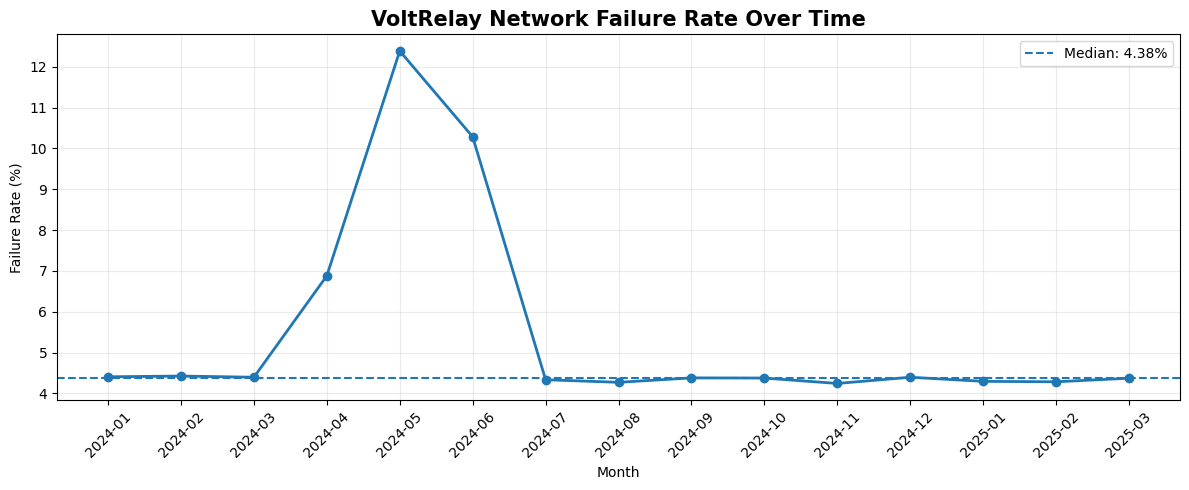

In [61]:
import matplotlib.pyplot as plt

plot_data = monthly_kpis[
    monthly_kpis["month"] <= "2025-03"
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["month"],
    plot_data["failure_rate_pct"],
    marker="o",
    linewidth=2
)

plt.axhline(
    plot_data["failure_rate_pct"].median(),
    linestyle="--",
    label=f"Median: {plot_data['failure_rate_pct'].median():.2f}%"
)

plt.title("VoltRelay Network Failure Rate Over Time", fontsize=15, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

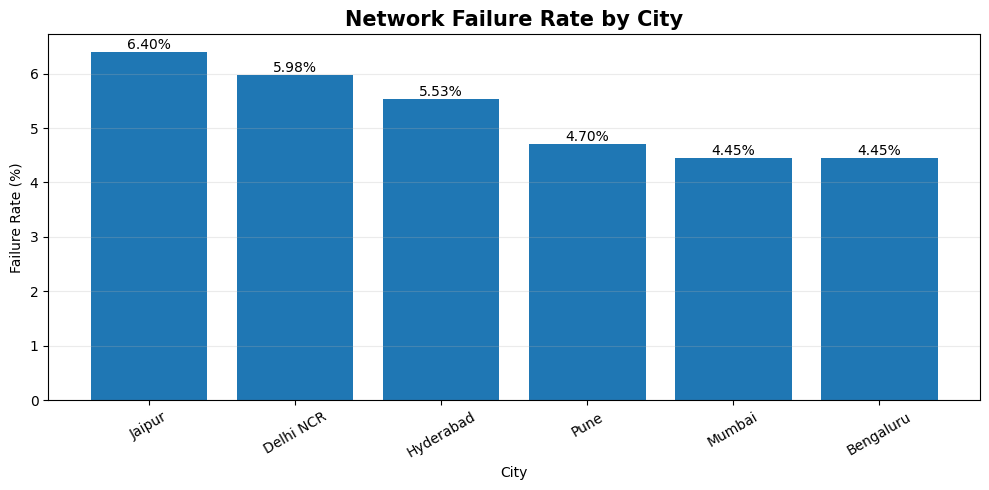

In [62]:
import matplotlib.pyplot as plt

city_plot = city_kpis.sort_values("failure_rate_pct", ascending=False)

plt.figure(figsize=(10, 5))

bars = plt.bar(
    city_plot["city"],
    city_plot["failure_rate_pct"]
)

plt.title("Network Failure Rate by City", fontsize=15, fontweight="bold")
plt.xlabel("City")
plt.ylabel("Failure Rate (%)")
plt.xticks(rotation=30)

for bar, value in zip(bars, city_plot["failure_rate_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.2f}%",
        ha="center",
        fontsize=10
    )

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

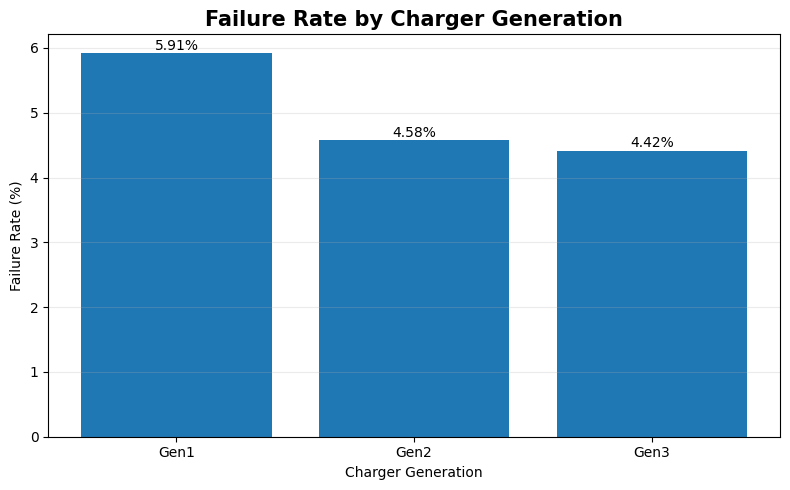

In [63]:
import matplotlib.pyplot as plt

gen_plot = generation_kpis.sort_values("failure_rate_pct", ascending=False)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gen_plot["charger_generation"],
    gen_plot["failure_rate_pct"]
)

plt.title("Failure Rate by Charger Generation", fontsize=15, fontweight="bold")
plt.xlabel("Charger Generation")
plt.ylabel("Failure Rate (%)")

for bar, value in zip(bars, gen_plot["failure_rate_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.2f}%",
        ha="center",
        fontsize=10
    )

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

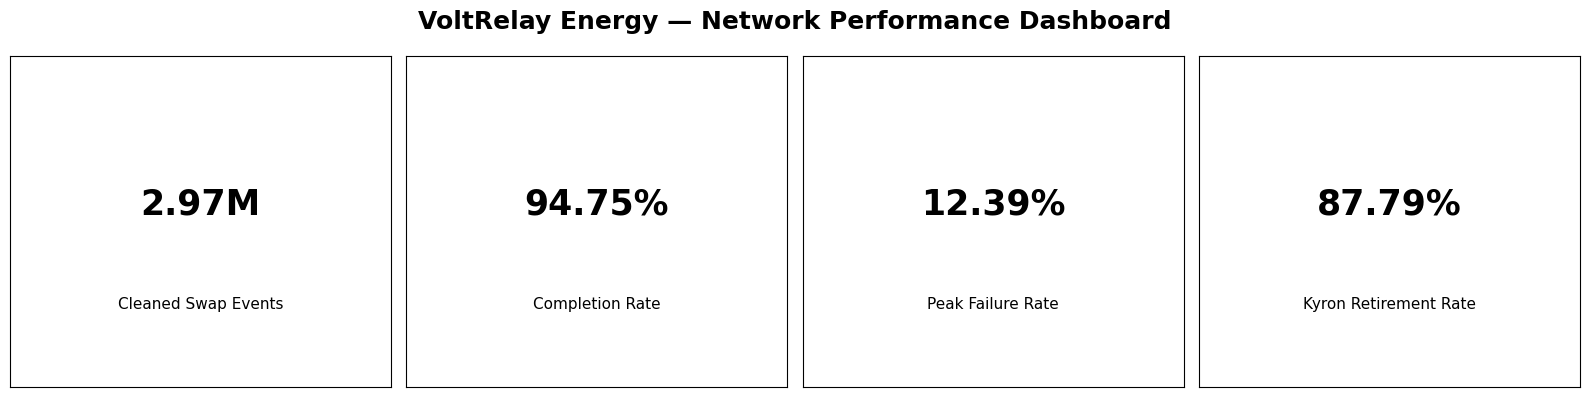

In [64]:
import matplotlib.pyplot as plt

overall_attempts = len(swap_events_clean)
overall_completed = (
    swap_events_clean["event_type"] == "swap_completed"
).sum()

overall_completion = overall_completed / overall_attempts * 100
overall_failure = 100 - overall_completion

peak_month = monthly_kpis.loc[
    monthly_kpis["failure_rate_pct"].idxmax()
]

kyron_retirement = battery_supplier.loc[
    battery_supplier["supplier"] == "Kyron",
    "retirement_rate_pct"
].iloc[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle(
    "VoltRelay Energy — Network Performance Dashboard",
    fontsize=18,
    fontweight="bold"
)

cards = [
    ("Cleaned Swap Events", f"{overall_attempts/1e6:.2f}M"),
    ("Completion Rate", f"{overall_completion:.2f}%"),
    ("Peak Failure Rate", f"{peak_month['failure_rate_pct']:.2f}%"),
    ("Kyron Retirement Rate", f"{kyron_retirement:.2f}%")
]

for ax, (title, value) in zip(axes, cards):
    ax.text(
        0.5, 0.55, value,
        ha="center", va="center",
        fontsize=25, fontweight="bold"
    )
    ax.text(
        0.5, 0.25, title,
        ha="center", va="center",
        fontsize=11
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(True)

plt.tight_layout()
plt.show()

In [ ]:
## 2. Methodology

The analysis follows a structured data analytics workflow:

1. **Data validation and cleaning**

   * Checked dataset dimensions, data types, duplicate records, missing values, categorical consistency, and date ranges.
   * Verified relationships between riders, stations, batteries, fleet partners, support tickets, and station telemetry.
   * Excluded two identified test stations from operational performance analysis.
   * Corrected invalid SOC/SOH values above 100 and negative distance values.
   * Corrected a documented firmware-related timestamp offset in the swap-event data.

2. **Exploratory analysis**

   * Evaluated network performance using completed swaps, failure rates, revenue, and queue wait.
   * Compared service reliability across months, cities, stations, and charger generations.
   * Examined battery supplier, manufacturing-lot, SOH, and retirement patterns.
   * Evaluated new-rider 30-day return behavior.

3. **Business-focused analysis**

   * Identified periods and locations with elevated service failures.
   * Investigated infrastructure characteristics associated with higher failure rates.
   * Investigated battery supplier and manufacturing-lot patterns to identify potential asset-quality risks.

4. **Visualization**

   * Developed focused visualizations for monthly failure trends, city-level reliability, and charger-generation performance.
   * Created an executive KPI dashboard summarizing the major network indicators.

5. **Interpretation**

   * Findings are presented as observed patterns and associations in the synthetic dataset and are not interpreted as causal relationships without controlled experimentation.
